# Baseline: TF-IDF + linear models

In [1]:
import gc
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from sklearn.svm import LinearSVC

SEED = 42
LABELS = ['human', 'ai', 'fusion']
SUB_N = 50_000
FULL_N = 100_000
INPUT = Path('/kaggle/input')
train = pd.read_parquet(next(INPUT.rglob('train_clean.parquet')), columns=['id', 'text', 'lang', 'domain', 'label', 'fold'])
test = pd.read_parquet(next(INPUT.rglob('test_clean.parquet')))
sample_sub = pd.read_csv(next(INPUT.rglob('sample_submission.csv')))

def strat_sample(df, n):
    return df.groupby(['label', 'lang', 'domain'], group_keys=False).sample(frac=min(n / len(df), 1), random_state=SEED)

tr, va = train[train.fold == 'train'], train[train.fold == 'val']
del train
sub_tr = strat_sample(tr, SUB_N)
tr = strat_sample(tr, FULL_N)
len(tr), len(va), len(sub_tr)

(99998, 54537, 50000)

## Features
Vocabulary and IDF are fitted on the train subsample only.

In [2]:
VECS = {
    'word': TfidfVectorizer(ngram_range=(1, 2), token_pattern=r'(?u)\w+|[^\w\s]', min_df=3, max_features=200_000, sublinear_tf=True, dtype=np.float32),
    'char': TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), min_df=3, max_features=200_000, sublinear_tf=True, dtype=np.float32),
}
def transform(vec, texts, chunk=10_000):
    return sp.vstack([vec.transform(texts.iloc[i:i + chunk]) for i in range(0, len(texts), chunk)]).tocsr()

X = {}
for name, vec in VECS.items():
    vec.fit(sub_tr.text)
    X[name] = {'sub': transform(vec, sub_tr.text), 'val': transform(vec, va.text)}

def feats(kind, split):
    return sp.hstack([X[k][split] for k in kind.split('+')]).tocsr()

def fit_eval(model, kind):
    model.fit(feats(kind, 'sub'), sub_tr.label)
    return f1_score(va.label, model.predict(feats(kind, 'val')), average='macro')

## Feature ablation

In [3]:
ablation = pd.Series({k: fit_eval(LinearSVC(C=.3), k) for k in ['word', 'char', 'word+char']}, name='macro_f1').round(4)
FEATS = ablation.idxmax()
ablation

word         0.8534
char         0.8535
word+char    0.8680
Name: macro_f1, dtype: float64

## Parameter search

In [4]:
MODELS = {
    'svc': LinearSVC,
    'lr': lambda **kw: LogisticRegression(max_iter=2000, **kw),
}
grid = pd.DataFrame([
    {'model': m, 'C': C, 'class_weight': str(cw), 'macro_f1': fit_eval(MODELS[m](C=C, class_weight=cw), FEATS)}
    for m, C, cw in product(MODELS, [.1, .3, 1, 3], [None, 'balanced'])
]).sort_values('macro_f1', ascending=False).round(4)
grid

,model,C,class_weight,macro_f1
15,lr,3.0,balanced,0.8800
14,lr,3.0,None,0.8789
13,lr,1.0,balanced,0.8774
12,lr,1.0,None,0.8758
3,svc,0.3,balanced,0.8693
11,lr,0.3,balanced,0.8688
2,svc,0.3,None,0.8680
5,svc,1.0,balanced,0.8672
4,svc,1.0,None,0.8666
10,lr,0.3,None,0.8655


## Best model on a 100k stratified sample of the train fold
Full 218k train fold does not fit into 30 GB RAM with char n-grams.

In [5]:
best = grid.iloc[0]
X_va = feats(FEATS, 'val')
del X
gc.collect()

def full_feats(df):
    return sp.hstack([transform(VECS[k], df.text) for k in FEATS.split('+')]).tocsr()

X_tr, X_te = full_feats(tr), full_feats(test)
cw = None if best.class_weight == 'None' else 'balanced'
model = MODELS[best.model](C=best.C, class_weight=cw).fit(X_tr, tr.label)
va_pred = model.predict(X_va)
print(best.to_dict())
print(classification_report(va.label, va_pred, labels=LABELS, digits=4))

{'model': 'lr', 'C': 3.0, 'class_weight': 'balanced', 'macro_f1': 0.88}
              precision    recall  f1-score   support

       human     0.7961    0.8945    0.8425     13408
          ai     0.9878    0.9898    0.9888     24375
      fusion     0.8976    0.8060    0.8493     16754

    accuracy                         0.9099     54537
   macro avg     0.8938    0.8968    0.8935     54537
weighted avg     0.9129    0.9099    0.9100     54537



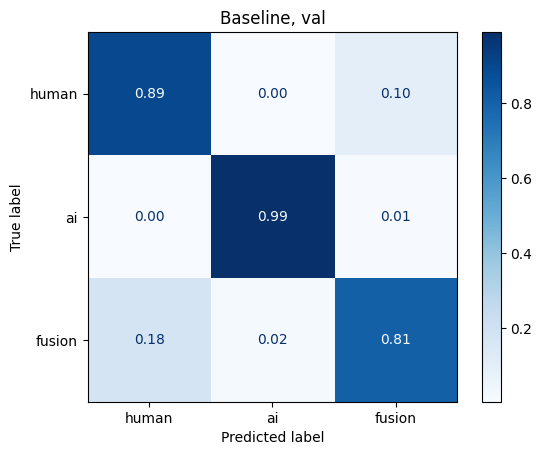

In [6]:
ConfusionMatrixDisplay.from_predictions(va.label, va_pred, labels=LABELS, normalize='true', cmap='Blues', values_format='.2f')
plt.title('Baseline, val')
plt.show()

## Stability across slices

In [7]:
def slice_f1(df, pred, by):
    return df.assign(pred=pred).groupby(by).apply(lambda d: f1_score(d.label, d.pred, average='macro')).round(4)

pd.concat({by: slice_f1(va, va_pred, by) for by in ['lang', 'domain']}).rename('macro_f1').to_frame()

/tmp/ipykernel_16/1454178251.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.assign(pred=pred).groupby(by).apply(lambda d: f1_score(d.label, d.pred, average='macro')).round(4)
/tmp/ipykernel_16/1454178251.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.assign(pred=pred).groupby(by).apply(lambda d: f1_score(d.label, d.pred, average='macro')).round(4)


macro_f1
lang   de-DE                     0.9205
       en-EN                     0.8867
domain arxiv_papers              0.8918
       blog_authorship_corpus    0.7768
       bundestag                 0.9206
       cnn_news                  0.9190
       euro_court_cases          0.9260
       gutenberg                 0.7746
       house_of_commons          0.8983
       student_essays            0.9056

## Save scores and submission

In [8]:
for name, df, Xs in [('val', va, X_va), ('test', test, X_te)]:
    pd.DataFrame(model.decision_function(Xs), columns=model.classes_, index=df.id).to_csv(f'{name}_scores_baseline.csv')

pred = pd.Series(model.predict(X_te), index=test.id)
sample_sub.assign(label=pred.loc[sample_sub.id].values).to_csv('submission_baseline.csv', index=False)
pd.read_csv('submission_baseline.csv').label.value_counts(normalize=True).round(3)

label
ai        0.516
human     0.273
fusion    0.211
Name: proportion, dtype: float64